# Introduzione a python
Questo capitolo descrive brevemente i principali strumenti che permettono di analizzare dati in modo esplorativo usando python come linguaggio di programmazione, jupyter come ambiente di elaborazione e introducendo le principali librerie del cosiddetto _python data science stack_ via via che queste si riveleranno necessarie

## I tipi di dati semplici e gli operatori
In python non esiste il concetto di _dichiarazione_: quando si vuole utilizzare una variabile le si assegna un valore, e quest'ultimo determina automaticamente il tipo della variabile e di conseguenza quali operazioni si possono effettuare su di essa, ovviamene solo fino a quando non vi venga memorizzato un nuovo valore o il riferimento a un oggettoIl linguaggio è comunque fortemente tipizzato, ma il _type checking_ viene fatto durante l'esecuzione.. I tipi di dati fondamentali sono quello booleano (`bool`, che fa riferimento alle costanti `True` e `False`), quello intero (`int`) e quello a virgola mobile (`float`). Ciò significa dunque che in python, a differenza di altri linguaggi, non esiste il tipo carattere: vedremo più avanti che le stringhe sono direttamente implementate come oggetti.

Il tipo di dato intero permette di memorizzare numeri interi, che si esprimono come successioni di una o più cifre eventualmente precedute da `+` (che si può omettere) o da `-` per indicarne il segno. Il tipo di dato a virgola mobile permette di memorizzare numeri con la virgola; anche in questo caso si utilizza di norma la notazione tipica in ambito informatico: si indica il segno, seguito dalle cifre intere, dal carattere `.` e dalle cifre decimali. Nel caso in cui si debbano specificare dei valori molto grandi o molto piccoli risulta però più pratico l'utilizzo della notazione _scientifica_ o _esponenziale_: si indica un valore di _mantissa_ (con o senza virgola) seguito dal carattere `E` (o `e`) e da un numero intero detto _esponente_, e tale espressione genera il valore numerico pari al prodotto della mantissa per `10` elevato all'esponente. Pertanto `1E9` e `1E-9` indicano rispettivamente un miliardo e un miliardesimo.

Se avete dubbi sul tipo di un'espressione, la funzione `type` restituisce il tipo corrispondente.

In [1]:
first_appearance = 1971
type(first_appearance)

int

In [2]:
weight = 71.6
type(weight)

float

In [3]:
type(True)

bool

A partire da valori booleani, interi o a virgola mobile è possibile costruire espressioni arbitrariamente complesse utilizzando degli _operatori_. La maggior parte di quelli che considereremo è di tipo _binario_ (cioè si applicano a due argomenti) e si utilizzano in modalità _infissa_ (il che significa che l'operatore si indica in mezzo ai suoi due argomenti). Gli operatori vengono utilizzati nella maggior parte dei linguaggi per codificare le operazioni aritmetico/logiche e le relazioni aritmetiche (utilizzando `+` per l'addizione, `!=` per la relazione di non uguaglianza e così via). La tabella seguente riassume i principali simboli utilizzati in python per questo tipo di operatori binari.

| Operazione | Simbolo |
|---|---|
| addizione | `+` |
| sottrazione | `-` |
| moltiplicazione | `*` |
| divisione (reale) | `/` |
| divisione (intera) | `//` |
| resto (modulo) | `%` |
| elevamento a potenza | `**` |
| uguale | `==` |
| diverso | `!=` |
| minore | `<` |
| minore o uguale | `<=` |
| maggiore | `>` |
| maggiore o uguale | `>=` |

Risulta opportuno sottolineare che esistono due diversi simboli per codificare la divisione tra numeri reali e quella tra numeri interi. In altre parole, la valutazione di `/` sarà sempre un numero in virgola mobile, anche nel caso in cui i due argomenti dovessero essere due interi e il primo fosse un multiplo del secondo. In molti linguaggi di programmazione (comprese le versioni di python precedenti alla 3.0) viene invece utilizzato il simbolo `/` per entrambe le divisioni, e in fase di esecuzione è il tipo degli operandi a stabilire quali delle due verrà effettivamente calcolata.

Sebbene la maggior parte degli operatori che considereremo sono di tipo binario, ne esistono anche di altri tipi: il simbolo `-` è un esempio di operatore _unario_ che cambia il segno dell'espressione che lo segue (esiste anche l'analogo, ma poco utile, operatore `+`). Vedremo più avanti che esiste anche uno speciale operatore _ternario_.

## I tipi di dati strutturati
Il linguaggio supporta nativamente i seguenti tipi strutturati: le liste, le stringhe, gli insiemi e i dizionari. Questi tipi sono brevemente descritti nei paragrafi seguenti.

### Le liste
In python, una lista è una struttura dati _eterogenea_ e ad _accesso posizionale_: pertanto in essa viene memorizzata tipicamente una sequenza di elementi, che possono essere di tipo diverso e a cui è possibile accedere direttamente specificando la corrispondente posizione. Una lista si può indicare in modo _estensivo_ separando i suoi elementi tramite virgola e racchiudendo il tutto tra parentesi quadre.

Nei nostri esperimenti faremo riferimento a un _dataset_ ottenuto modificando un opportuno sottoinsieme del Superhero Database. Gli esempi faranno quindi riferimento al mondo dei supereroi, ognuno dei quali sarà descritto tramite:
- il suo nome,
- la sua identità,
- il luogo in cui è nato,
- l'editore dei corrispondenti fumetti/film/serie tv,
- l'altezza in cm.,
- il peso in kg.,
- il genere,
- l'anno della prima apparizione,
- il colore degli occhi,
- il colore dei capelli,
- un indice di forza (in una scala quantitativa da 0 a 100),
- un indice di intelligenza (in una scala qualitativa i cui valori sono low, moderate, average, good, e high).

La proprietà di eterogeneità ci permette di usare una lista per aggregare le informazioni che descrivono un supereroe:

In [4]:
iron_man = ['Iron Man',
           'Tony Stark',
           'Long Island, New York',
           'Marvel Comics',
           198.51,
           191.85,
           'M',
           1963,
           'Blue',
           'Black',
           85,
           'high']
type(iron_man)

list

In effetti vedremo che ci sono modi molto più interessanti di codificare un _record_ di informazioni, così come ci renderemo conto che nei fatti le liste contengono di norma valori di tipo omogeneo, ma per ora quello che ci interessa è semplicemente vedere quali sono le modalità principali di utilizzo di questo tipo di struttura dati.

Per accedere a un elemento in una lista, basta specificare dopo una variabile che la referenzia (ma ovviamente si potrebbe utilizzare anche la lista stessa) una coppia di parentesi quadre contenente la posizione dell'elemento, conteggiata a partire da `0`:

In [5]:
iron_man[1]

'Tony Stark'

Se si specifica un valore negativo per la posizione, a questo viene automaticamente sommata la lunghezza della lista. Pertanto la posizione `-1` identifica l'ultimo elemento della lista, la posizione `-2` corrisponde al penultimo e così via:

In [6]:
iron_man[-2]

85

È anche possibile indicare un intervallo di posizioni per recuperare la sottolista corrispondente: questa operazione, che prende il nome di _list slicing_, si effettua indicando tra parentesi quadre la posizione del primo elemento da inserire, seguita da un carattere di due punti e dalla posizione del primo elemento da escludere. Il peso e l'altezza di Tony Stark, essendo memorizzati in quinta e sesta posizione, si potranno quindi ottenere congiuntamente nel seguente modo (ricordando che gli indici delle posizioni partono da zero):

In [7]:
iron_man[4:6]

[198.51, 191.85]

Il riferimento a un _list slicing_ si può fare anche utilizzando indici negativi (o mescolando indici positivi e negativi):

In [8]:
iron_man[-4:-2]

['Blue', 'Black']

Dover specificare la posizione del primo elemento da escludere sembra controintuitivo rispetto alla scelta più naturale di indicare la posizione dell'ultimo elemento da includere. In realtà in questo modo risulta più facile scrivere codice che elabora porzioni successive in una lista.

Le liste sono inoltre una struttura dati a dimensione _dinamica_, nel senso che oltre a modificare gli elementi in essa contenuti è anche possibile rimuovere uno o più di tali elementi, oppure aggiungerne di nuovi. Python mette a disposizione varie operazioni che agiscono sulle liste: il paragrafo che segue introduce alcuni esempi, ma il suo scopo è più quello di chiarire la differenza tra i concetti di operatori, funzioni e metodi.

### Operatori, funzioni e metodi per le liste
In python è possibile usare le liste (ma anche gli altri tipi di dati che vedremo più avanti) come
- argomenti di operatori,
- argomenti di funzioni,
- oggetti su cui invocare metodi.
Per esemplificare l'uso di questi tre tipi di strumenti conviene ragionare in termini di una lista utilizzata come se fosse un array, memorizzando dunque una successione di valori dello stesso tipo, per esempio i nomi di alcuni supereroi:

In [9]:
names = ['Aquaman', 'Ant-Man', 'Batman', 'Black Widow',
         'Captain America', 'Daredavil', 'Elektra', 'Flash',
         'Green Arrow', 'Human Torch', 'Hancock', 'Iron Man',
         'Mystique', 'Professor X', 'Rogue', 'Superman',
         'Spider-Man', 'Thor', 'Northstar']

#### Operatori
Python mette inoltre a disposizione l'operatore binario `in` che implementa la relazione di appartenenza: se `e` è un'espressione e `l` una lista, l'espressione `e in l` viene valutata vera se il valore dell'espressione occorre in una posizione qualsiasi della lista e falsa altrimenti

In [10]:
'Thing' in names

False

In [11]:
'Human Torch' in names

True

Un altro operatore (unario) specifico per le liste è `del`, che permette di eliminare un elemento da una lista indicandone la relativa posizione: per esempio, eseguendo la cella seguente viene cancellata la stringa contenuta nella prima posizione di `names`

In [12]:
del names[0]

Va sottolineato come `del` non restituisca un valore: successivamente alla sua esecuzione, la lista corrispondente avrà un elemento in meno, e in questo specifico caso quello che prima era il secondo elemento diventa ora il primo, e così via:

In [13]:
names[0]

'Ant-Man'

#### Funzioni
Python prevede inoltre alcune funzioni che elaborano liste, come per esempio `len` che restituisce il numero di elementi contenuti in una lista, a cui si fa di norma riferimento denotandolo come la _lunghezza_ della lista stessa:

In [14]:
len(names)

18

#### Metodi
Python è un linguaggio di programmazione che implementa (anche) il paradigma orientato a oggetti, e le liste (così come gli altri tipi di dati che vedremo più avanti) sono a tutti gli effetti oggetti su cui è possibile invocare metodi.
Supponiamo di voler mettere in ordine alfabetico i nomi dei supereroi (la lista è quasi in ordine, l'unico elemento fuori posto è l'ultimo): la corrispondente operazione di ordinamento richiede di invocare sulla lista il metodo `sort` (usando la _dot notation_ tipica della programmazione orientata agli oggetti).

In [15]:
names.sort()

Così come l'operatore `del`, tale metodo però non restituisce alcun valore, in quanto l'ordinamento è eseguito _in place_: dopo l'invocazione, gli elementi della lista saranno stati riposizionati in modo da riflettere l'ordinamento.
Possiamo convincercene facilmente visualizzando per esempio gli ultimi cinque elementi di `names`:

In [16]:
names[-5:]

['Professor X', 'Rogue', 'Spider-Man', 'Superman', 'Thor']

L'invocazione di metodi (e di funzioni) prevede in python anche la possibilità di specificare degli argomenti _opzionali_: si tratta di argomenti, identificati da un nome, che possono essere omessi, e in tal caso assumono un valore predefinito all'atto dell'invocazione. Per poterne specificare un valore diverso da quello predefinito è sufficiente indicare, dopo gli eventuali altri argomenti, un'espressione del tipo `<nome>=<valore>`, separando tramite virgola la specificazione di più argomenti opzionali. Per esempio il metodo `sort` effettua l'ordinamento in verso non decrescente, e l'argomento opzionale `reversed` permette di invertire tale verso:

In [17]:
names.sort(reverse=True)

In [18]:
names.sort(key=len)

In [19]:
names

['Thor',
 'Rogue',
 'Flash',
 'Batman',
 'Hancock',
 'Elektra',
 'Ant-Man',
 'Superman',
 'Mystique',
 'Iron Man',
 'Northstar',
 'Daredavil',
 'Spider-Man',
 'Professor X',
 'Human Torch',
 'Green Arrow',
 'Black Widow',
 'Captain America']

Un'altra caratteristica di python è quella di poter specificare una funzione come argomento di un metodo (o di un'altra funzione); ciò si può fare o indicando il nome della funzione, oppure usando una _lambda function_ o _funzione anonima_: una funzione che viene definita senza darle un nome ma definendo direttamente come i suoi argomenti devono essere trasformati nel valore da restituire. Più precisamente, la sintassi `lambda x: <espressione>` definisce una funzione che ha un argomento il cui nome simbolico è `x` e che restituisce l'espressione dopo il carattere di due punti (che di norma dipenderà da `x`).

Un esempio che mette insieme l'uso di argomenti opzionali e di funzioni anonime si trova nella cella seguente, in cui la lista dei nomi viene ordinata non in modo alfabetico, bensì in funzione della lunghezza dei nomi stessi, specificando tramite l'argomento opzionale `key` una funzione anonima che trasformerà ogni elemento della lista in un valore su cui basare l'ordinamento.

In [20]:
lambda n: n+1

<function __main__.<lambda>(n)>

In [21]:
successore = lambda n: n+1
successore(9)

10

In [22]:
names.sort(key=lambda n:len(n))
names

['Thor',
 'Rogue',
 'Flash',
 'Batman',
 'Hancock',
 'Elektra',
 'Ant-Man',
 'Superman',
 'Mystique',
 'Iron Man',
 'Northstar',
 'Daredavil',
 'Spider-Man',
 'Professor X',
 'Human Torch',
 'Green Arrow',
 'Black Widow',
 'Captain America']

Un altro metodo invocabile su una lista è `insert`, che permette di aggiungere un elemento a una lista esistente, specificando rispettivamente come secondo e primo argomento l'elemento da aggiungere e la posizione in cui inserirlo: per esempio nella cella seguente viene re-inserito Aquaman in modo da mantenere `names` in ordine

In [23]:
names.insert(4, 'Aquaman')
names[:6]

['Thor', 'Rogue', 'Flash', 'Batman', 'Aquaman', 'Hancock']

### Le tuple
Una tupla è una lista immutabile: una volta creata non è possibile modificare i suoi contenuti. Una tupla viene indicata in modo analogo a una lista, con l'unica differenza che i suoi contenuti sono delimitati da parentesi tonde.

In [24]:
rogue = ('Rogue',
         'Anna Marie',
         'Caldecott County, Mississippi',
         'Marvel Comics',
         173.1,
         54.39,
         'F',
         1981,
         'Green',
         'Brown / White',
         10,
        'good')

L'accesso a un elemento di una tupla viene fatto in modo posizionale usando la medesima sintassi introdotta per le liste:

Qualora si tenti di modificare un elemento in una tupla, l'esecuzione verrà però bloccata emettendo un errore:

In [25]:
try:
    rogue[-2]=70
except TypeError:
    print('Non si possono modificare gli elementi di una tupla')

Non si possono modificare gli elementi di una tupla


Va notato che in python gli errori di esecuzione vengono emessi utilizzando il meccanismo delle eccezioni, che nella cella precedente vengono gestite in modo analogo a quanto succede per esempio in Java: il blocco di istruzioni coinvolto è quello che segue la parola chiave `try`, e le istruzioni dopo `except` vengono eseguite solo se viene lanciata un'eccezione del tipo specificato. A seguito di questo errore, la tupla manterrà i suoi valori originali, restando quindi effettivamente invariata:

In [26]:
rogue

('Rogue',
 'Anna Marie',
 'Caldecott County, Mississippi',
 'Marvel Comics',
 173.1,
 54.39,
 'F',
 1981,
 'Green',
 'Brown / White',
 10,
 'good')

Una tupla può essere utilizzata facendo riferimento agli stessi operatori e alle stesse funzioni messi a disposizione per le liste (come per esempio `in` e `len`), escludendo ovviamente le operazioni che modificano la tupla stessa (come `sort`).

L'immutabilità delle tuple le rende da preferire rispetto alle liste in tutti i casi in cui si vuole impedire che dei dati vengano modificati, per esempio a causa di un bug; inoltre la loro elaborazione è in molti casi più efficiente di quella delle liste.

<div class='alert alert-info'>
    Va notato che la sintassi per la descrizione delle tuple diventa problematica quando si vuole indicare una tupla contenente un unico elemento, in quanto per esempio '(1)' viene interpretato come valore '1' tra parentesi tonde. La soluzione in casi come questi è quella di fare seguire l'unico elemento della tupla da una virgola, scrivendo per esempio '(1,)'. Come regola generale, infatti, è possibile aggiungere una virgola alla fine di una tupla (o di una lista) senza variarne i contenuti.
</div>

### Le stringhe
Le stringhe sono implementate come tuple di caratteri, e quindi su di esse è possibile eseguire tutte le operazioni che si eseguono sulle tuple:

In [27]:
name = rogue[1]
name[3]

'a'

Si verifica facilmente come si tratti di tuple e non di liste, in quanto i contenuti non sono modificabili:

In [28]:
try:
    name[3]='A'
except TypeError:
    print('Non si possono modificare i contenuti di una stringa')

Non si possono modificare i contenuti di una stringa


### Gli insiemi
Python implementa direttamente un tipo di dato per gli insiemi, intesi come collezione finita di elementi tra loro distinguibili e non memorizzati in un ordine particolare. A differenza delle liste e delle tuple, gli elementi non sono quindi associati a una posizione e non è possibile che un insieme contenga più di un'istanza di un medesimo elemento. Non utilizzeremo questo tipo di dato.

### I dizionari
I dizionari servono a memorizzare delle associazioni tra oggetti, in analogica con il concetto matematico di funzione. È quindi possibile pensare a essi come a insiemi di coppie (chiave, valore), dove una data chiave non occorre più di una volta.

Un dizionario viene descritto indicando ogni coppia separando chiave e valore con il carattere di due punti, separando le varie coppie con delle virgole e racchiudendo il tutto tra parentesi graffe. Possiamo per esempio usare un dizionario per rappresentare un record in modo più elegante rispetto alla precedente scelta basata sulle liste:

In [29]:
rogue = {'name': 'Rogue',
         'identity': 'Anna Marie',
         'birth_place': 'Caldecott County, Mississippi',
         'publisher': 'Marvel Comics',
         'height': 173.1,
         'weight': 54.39,
         'gender': 'F',
         'first_appearance': 1981,
         'eye_color': 'Green',
         'hair_color': 'Brown / White',
         'strength': 10,
         'intelligence': 'good'}

L'accesso, in lettura o scrittura, agli elementi di un dizionario viene fatto con una notazione che ricorda quella di liste e tuple: si specifica all'interno di parentesi quadre la chiave per ottenere o modificare il valore corrispondente:

In [30]:
rogue['identity']

'Anna Marie'

È proprio questa modalità di accesso che fa sì che i dizionari rappresentino una scelta più elegante per memorizzare un record: `rogue['identity']` è sicuramente più leggibile di `rogue[1]`. Va notato che il prezzo da pagare per la leggibilità è un'efficienza potenzialmente minore nelle operazioni di accesso (normalmente le liste sono implementate con una logica simile a quella degli array e dunque hanno un tempo di accesso costante ai loro elementi, mentre i dizionari sono implementati tramite tabelle di hash, pertanto l'accesso è a tempo costante solo se non avvengono collisioni).

Se si tenta di accedere in lettura a un dizionario specificando una chiave inesistente viene lanciata un'eccezione (`KeyError`), mentre accedendovi in scrittura la specificazione di una chiave inesistente comporterà l'aggiunta della corrispondente coppia (chiave, valore) al dizionario.

L'operatore `in` introdotto per le liste può anche essere utilizzato per i dizionari: più precisamente, l'espressione `k in d` restituisce `True` se `k` è una chiave valida per il dizionario `d`.

## Strutture di controllo
Python gestisce il flusso di esecuzione tramite le tipiche strutture di controllo di sequenza, selezione e iterazione. La sequenza viene implementata semplicemente indicando le istruzioni, una per riga, in ordine di esecuzione: per esempio la cella seguente crea due liste, una con nomi di supereroi e un'altra con i corrispondenti anni di prima apparizione, e le memorizza nelle variabili `names` e `years`.

In [31]:
names = ['Aquaman', 'Ant-Man', 'Batman', 'Black Widow',
         'Captain America', 'Daredavil', 'Elektra', 'Flash',
         'Green Arrow', 'Human Torch', 'Hancock', 'Iron Man',
         'Mystique', 'Professor X', 'Rogue', 'Superman',
         'Spider-Man', 'Thor', 'Northstar']

years = [1941, 1962, None, None, 1941,
         1964, None, 1940, 1941, 1961,
         None, 1963, None, 1963, 1981,
         None, None, 1962, 1979]

Il valore speciale `None` è stato utilizzato nei casi in cui non risulta disponibile l'anno di prima apparizione di un supereroe. In queste situazioni si parla di _valori mancanti_ (o si utilizza l'equivalente termine inglese _missing values_) che di norma vengono indicati con la sigla NA (dall'inglese "not available"). La scelta di `None` come valore per codificare gli elementi mancanti è puramente arbitraria: l'eterogeneità delle liste ci avrebbe permesso di utilizzare per esempio la stringa `'NA'` o altri valori (anche espressioni numeriche che non indicano un anno). In realtà vedremo più avanti che esistono altre modalità che permettono di memorizzare ed elaborare i dati in modo più agevole.

Immaginiamo di voler conteggiare, anno per anno, il numero totale di apparizioni, calcolando quelle che in statistica vengono chiamate le _frequenze assolute_ del numero di apparizioni. Un approccio classico è quello di utilizzare un contatore per ogni anno, scandire la lista delle prime apparizioni e incrementare di volta in volta il contatore corrispondente all'anno trovato. Una struttura dati particolarmente adeguata per aggregare i contatori è un dizionario, in cui le chiavi corrispondono agli anni. La scansione di una lista viene effettuata in python da una delle due strutture iterative, il _ciclo for_. A differenza di quanto succede di norma, non si tratta di un ciclo numerato bensì di un ciclo che esegue il suo corpo in corrispondenza di ogni elemento di un _oggetto iterabile_. Liste e tuple sono appunto gli esempi più semplici di oggetti iterabili: immaginando che `lista` sia una lista da scandire (ma andrebbe bene anche una tupla) e che esista una funzione `elabora` che accetta un argomento, la sintassi
```
for elemento in lista:
    elabora(elemento)
```
implementa appunto un ciclo for, in cui `elemento` rappresenta una variabile che conterrà a ogni iterazione uno degli elementi. In particolare, liste e tuple vengono scandite in ordine di posizione, quindi `elemento` conterrà il primo elemento di `lista` durante la prima iterazione, il suo secondo elemento durante la seconda iterazione e così via. Notate anche che le funzioni si invocando usando la sintassi tipica basata sull'uso di parentesi tonde. Infine, va sottolineato che la seconda riga inizia più a destra della prima: in molti linguaggi questa tecnica (detta di _indentazione_) ha lo scopo puramente visuale di mettere in evidenza l'istruzione o le istruzioni che vengono ripetute nel ciclo (il _corpo_ del ciclo). In python l'indentazione è invece obbligatoria per indicare quali sono le istruzioni che compongono il corpo del ciclo (cosa che negli altri linguaggi viene fatta utilizzando per esempio le parentesi graffe). Non esiste una regola prefissata che indichi _come_ effettuare l'indentazione: si può usare un carattere di tabulazione, oppure alcuni caratteri di spazio. L'unica limitazione è quella di mantenere la stessa scelta una volta che questa è stata fatta: se si decide di indentare il corpo di un ciclo usando, per esempio, tre spazi, tutte le istruzioni del corpo dovranno essere indentate di tre spazi.

Tornando al problema di effettuare il conteggio del numero di apparizioni al variare degli anni, un primo tentativo che utilizza un dizionario per memorizzare i relativi contatori potrebbe essere il seguente:
```
# non funziona!
counts = {}
for y in years:
    counts[y] += 1
```
In realtà tale codice non funzionerebbe, perchè la prima istruzione crea un dizionario `counts` vuoto, e quindi il primo accesso che verrebbe fatto utilizzerebbe una chiave che non esiste, causando il lancio di un'eccezione. È pertanto necessario verificare di volta in volta che l'anno considerato sia una chiave esistente (il che significa che l'anno considerato è già stato trovato precedentemente, e quindi il corrispondente contatore esiste già e va solamente incrementato) oppure no (e dunque il contatore va inizializzato). È quindi necessario utilizzare l'operatore `in` unitamente a una struttura di selezione, e precisamente una if-else. La sintassi di questa struttura è la seguente:
```
if <condizione>:
    <istruzione_se_condizione_vera>
else:
    <istruzione_se_condizione_falsa>
```
e la sua semantica è quella che ci si aspetta: la condizione tra la parola chiave `if` e il carattere di due punti viene valutata: se risulta vera viene eseguita l'istruzione alla linea seguente, altrimenti viene eseguita l'istruzione dopo la parola chiave `else`. Anche in questo caso l'indentazione permette di identificare quali istruzioni debbano essere eseguite nei due rami della selezione. La cella seguente contiene un'implementazione (stavolta funzionante) del codice che conteggia le apparizioni per anno.

In [32]:
counts = {}
for y in years:
    if y in counts:
        counts[y] += 1
    else:
        counts[y] = 1

Il risultato è il seguente:

In [33]:
counts

{1941: 3,
 1962: 2,
 None: 7,
 1964: 1,
 1940: 1,
 1961: 1,
 1963: 2,
 1981: 1,
 1979: 1}

Notate che una coppia fa riferimento alla chiave `None`, che sarà relativa al numero di casi mancanti. Supponiamo di voler visualizzare i conteggi visualizzando prima l'anno con il maggior numero di apparizioni, per poi procedere in ordine decrescente. Un possibile modo di procedere è quello di "convertire" `counts` nella corrispondente tupla di coppie e poi ordinare quest'ultima. La prima operazione si effettua facilmente invocando sul dizionario il metodo `items`. La seconda operazione è più complessa, perchè è necessario basare l'ordinamento sul secondo elemento di ogni coppia. Nella cella seguente si utilizza l'argomento opzionale `key` della funzione `sorted` e una funzione anonima per specificare il criterio su cui basare l'ordinamento. L'esempio utilizza anche l'argomento opzionale `reverse` per ottenere gli anni ordinati a partire da quello con il maggior numero di apparizioni.

In [34]:
pairs = tuple(counts.items())
sorted(pairs, key=lambda p: p[1], reverse=True)

[(None, 7),
 (1941, 3),
 (1962, 2),
 (1963, 2),
 (1964, 1),
 (1940, 1),
 (1961, 1),
 (1981, 1),
 (1979, 1)]

## Funzioni
Il calcolo delle frequenze è un'operazione che viene fatta molto spesso, quindi conviene scrivere una funzione che ci eviti di dover ricopiare ogni volta la decina di linee che abbiamo scritto. La definizione di una funzione in python (a parte il caso delle funzioni anonime) viene fatta utilizzando la parola chiave `def` seguita dal nome del metodo e dai nomi simbolici per i suoi argomenti, separati da virgole e racchiusi tra parentesi (fanno ecccezione gli eventuali argomenti opzionali). La definizione procede con un carattere di due punti e dal corpo della funzione le cui istruzioni devono essere indentate di un livello.

La cella seguente riporta un esempio di semplice definizione di funzione che mette insieme il codice scritto finora in modo da accettare una generica lista e di restituirne le frequenze assolute ordinate dalla più grande alla più piccola.

In [35]:
def get_sorted_counts(sequence):
    counts = {}

    for x in sequence:
        if x in counts:
            counts[x] += 1
        else:
            counts[x] = 1

    pairs = counts.items()
    return sorted(pairs, key=lambda p:p[1], reverse=True)

get_sorted_counts(years)

[(None, 7),
 (1941, 3),
 (1962, 2),
 (1963, 2),
 (1964, 1),
 (1940, 1),
 (1961, 1),
 (1981, 1),
 (1979, 1)]

## Importare moduli
Il meccanismo con cui in python si organizzano progetti software complessi e si riutilizza il codice è basato sul concetto di _modulo_. In pratica un modulo è un file che contiene la definizione di una o più funzioni o classi. L'importazione può riguardare un intero modulo oppure solo uno (o più) dei suoi elementi. Tramite i moduli è inoltre possibile utilizzare librerie standard o sviluppate da terze parti. Consideriamo per esempio la funzione `get_sorted_counts` che abbiamo appena scritto: se esistesse un dizionario in cui le chiavi inesistenti venissero automaticamente associate a un valore nullo, si potrebbe semplificare notevolmente il corpo della funzione, rendendo corretto il primo tentativo di implementazione che avevamo fatto. In effetti, una tale variante di dizionario esiste: si chiama `defaultdict` ed è disponibile nel modulo `collections` (uno dei moduli standard di python). La cella seguente importa questo nuovo tipo di dato:

In [36]:
from collections import defaultdict

e lo mette a disposizione: l'espressione `defaultdict(<tipo>)` crea un dizionario vuoto e il tipo indicato come argomento determina quale sarà il valore predefinito per le chiavi. Nel nostro caso, l'argomento `int` fa sì che tale valore predefinito sia `0`. Ciò permette di riscrivere la funzione `get_sorted_counts` in modo che non sia più necessario verificare preventivamente l'esistenza dei contatori.

In [37]:
def get_sorted_counts(sequence, sort='freq'):
    counts = defaultdict(int)

    for x in sequence:
        counts[x] += 1

    pairs = counts.items()
    index = 1 if sort=='freq' else 0
    reverse = (sort=='freq')
    return sorted(pairs, key=lambda p:p[index], reverse=reverse)

In [38]:
get_sorted_counts(years, sort='freq')

[(None, 7),
 (1941, 3),
 (1962, 2),
 (1963, 2),
 (1964, 1),
 (1940, 1),
 (1961, 1),
 (1981, 1),
 (1979, 1)]

Quando è necessario importare molti elementi da uno o più moduli, potrebbe capitare che due o più elementi in moduli diversi abbiano lo stesso nome. Per evitare situazioni di questo genere, è opportuno importare un intero modulo: per esempio, l'istruzione

In [39]:
import numpy

importa il modulo corrispondente alla libreria numpy, che mette a disposizione una struttura dati simile agli array (in cui l'omogeneità dei dati ivi contenuti permette di effettuare calcoli in modo più efficiente rispetto all'uso delle liste o delle tuple). Dopo che un modulo è stato importato, è possibile accedere a un suo generico elemento usando il nome del modulo, seguito da un punto e dal nome dell'elemento in questione. Per esempio, la cella successiva calcola il cosiddetto _argmax_ della lista `index` (dopo averla modificata eliminando i valori `None` in essa presenti), e cioè l'indice in cui si trova un suo elemento massimo.

In [40]:
[i**2 for i in range(4) if i % 2 == 0] # list comprehension

[0, 4]

In [41]:
years = [y for y in years if y is not None]
print(numpy.argmax(years))

9


Indicare il nome di un modulo per poter accedere ai suoi elementi ha spesso l'effetto di allungare il codice, diminuendone al contempo la leggibilità. È per questo motivo che è possibile importare un modulo specificando un nome alternativo, più corto. È quello che succede nella seguente cella, che importa `numpy` e `pandas`, un modulo che mette a disposizione delle classi per gestire i dati organizzandoli in serie e in tabelle.

In [42]:
import numpy as np
import pandas as pd

<div class="alert alert-info">
    Questo modo di importare numpy e pandas usando i nomi alternativi <code>np</code> e <code>pd</code> fa riferimento a una convenzione molto diffusa tra gli sviluppatori. Vale la pena mantenere questa convenzione, così che chi legge il codice possa capire a colpo d'occhio a quale modulo si fa riferimento.
</div>

I moduli più complessi sono organizzati in strutture gerarchiche chiamate _package_, in modo non dissimile a quanto avviene per esempio in Java. La seguente cella importa il modulo `pyplot` che è contenuto nel modulo `matplotlib` (matplotlib è la libreria di riferimento in python per la creazione di grafici)

In [43]:
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

<div class="alert alert-info">
    L'invocazione di <code>plt.style.use</code> ha uno scopo puramente estetico: serve infatti a impostare uno stile per la visualizzazione dei grafici prodotti con matplotlib.
</div>

## Disegnare grafici
Il modulo `plt` può essere usato per produrre vari tipi di grafici. In generale le funzioni di questo modulo che generano un grafico basato su una serie di punti accettano come argomenti due liste contenenti rispettivamente le ascisse e le ordinate dei punti stessi. La funzione `get_sorted_counts` restituisce però una lista di coppie e non due liste di valori singoli. Se interpretiamo questa lista come una matrice, la trasposta di quest'ultima equivarrà a una lista che contiene esattamente le due liste che ci interessano. Per effettuare questa operazione risulta conveniente utilizzare il tipo di dato base messo a disposizione da numpy, `np.array`. Passando una lista (o una tupla, una lista di liste e così via) come argomento a `np.array` si crea un oggetto che corrisponde al corrispondente array. Su questo oggetto è possibile invocare il metodo `transpose` che restituisce il trasposto dell'array.

<div class="alert alert-warning">
    Tecnicamente, il metodo <code>transpose</code> restituisce una vista dell'array originale in modo che questo appaia trasposto. Ciò significa che non viene creato un nuovo oggetto e quindi le modifiche fatte al valore restituito andranno ad alterare anche l'array di partenza. Va anche notato il fatto che se si tenta di trasporre un array monodimensionale <code>transpose</code> restituirà una vista identica all'argomento specificato.
</div>

In [44]:
np.array(get_sorted_counts(years, sort='year')).transpose()

array([[1940, 1941, 1961, 1962, 1963, 1964, 1979, 1981],
       [   1,    3,    1,    2,    2,    1,    1,    1]])

Usando una caratteristica di python è possibile assegnare le due liste ottenute direttamente a due variabili `x` e `y`:

In [45]:
a = 'foo'
b = 'bar'
a, b = (b, a)

In [46]:
x, y = np.array(get_sorted_counts(years, sort='year')).transpose()

<div class="alert alert-info">
    Questa caratteristica di python, nota con il nome di unpacking, permette per esempio di scambiare i contenuti di due variabili 'a' e 'b' senza ricorrere a una variabile temporanea, utilizzando l'assegnamento 'a, b = b, a'
</div>

Le due variabili `x` e `y` possono dunque essere passate come argomento al metodo `plt.bar` per produrre un grafico a barre che visualizzi le frequenze assolute degli anni di prima apparizione:

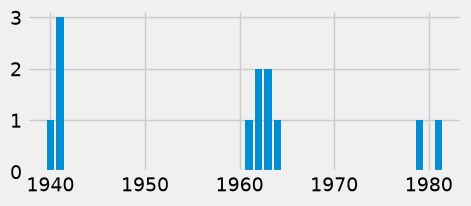

In [47]:
plt.rc('figure', figsize=(5.0, 2.0))
plt.bar(x, y)
plt.show()

Vale la pena commentare in modo approfondito le righe di codice appena eseguite, specificando la differenza tra _generare_ e _visualizzare_ un grafico. In generale, invocare un metodo in matplotlib ha l'effetto di _modificare_ l'aspetto di un grafico (partendo ovviamente da un grafico vuoto). Ciò permette di sovrapporre diversi grafici, o di cambiare le etichette sugli assi e così via. Metodi come `plt.bar` visualizzano il grafico che corrisponde alla modifica apportata dal metodo eseguito, restituendo nel contempo dell'output testuale (una descrizione delle varie componenti del grafico stesso) che nella maggior parte dei casi non è particolarmente interessante. È per questo che l'ultima istruzione eseguita è `plt.show()`: questo metodo visualizza il grafico senza restituire alcunchè.

Infine, la seconda linea ci permette di impostare le dimensioni dei grafici: i valori predefiniti genererebbero infatti delle figure un po' troppo grandi.

## Leggere dati da file (e un po' di trucchi)
Di solito la quantità di dati da analizzare è tale che non è pensabile di poterli immettere manualmente in una o più lista come abbiamo fatto noi. Normalmente i dati sono memorizzati su un file ed è necessario leggerli. Prendiamo in considerazione il file di testo `heroes.csv` contenuto nella directory `data`: esso contiene 735 righe, ognuna con le informazioni relative a un supereroe, separate da virgola. Le prime tre righe del file sono indicate di seguito.
```
name;identity;birth_place;publisher;height;weight;gender;first_appearance;eye_color;hair_color;strength
A-Bomb;Richard Milhouse Jones;Scarsdale, Arizona;Marvel Comics;203;441;M;2008;Yellow;No Hair;100
Agent Bob;Bob;;Marvel Comics;178;81;M;2007;Brown;Brown;10
```
Il formato CSV (comma separated values) indica un record su ogni riga, separando i campi corrispondenti con un carattere speciale che di norma, ma non sempre, è la virgola. Come si può vedere, nel nostro caso la prima riga indica il tipo di dati presente in ogni riga (sono gli stessi a cui abbiamo fatto riferimento finora), viene usato il punto e virgola per separare i campi (ciò permette di inserire delle virgole nei luoghi di nascita, come nel primo record) e possono esistere dei valori mancanti (quali per esempio il luogo di nascita nel secondo record).

La cella seguente legge i contenuti del file e li inserisce nella lista `heroes`.

In [48]:
import csv

with open('data/heroes.csv', 'r') as heroes_file:
    heroes_reader = csv.reader(heroes_file, delimiter=';', quotechar='"')
    heroes = list(heroes_reader)[1:]

Nella cella:
- l'apertura del file è fatta utilizzando la parola chiave `with`: nelle istruzioni indentate che seguono è possibile usare `heroes_file` per fare riferimento all'oggetto che descrive il file, e quest'ultimo sarà automaticamene chiuso, anche nel caso in cui vengano lanciate eccezioni, all'uscita del corpo di `with`;
- la funzione che apre il file accetta come primo argomento il pathname corrispondente e come secondo una stringa che indica come effettuare l'accesso: `'rb'` indica lettura in modalità binaria, cosa che permette di non doversi preoccupare di dover gestire come il sistema operativo indica la fine linea nei file di testo;
- la lettura effettiva del file è demandata al modulo `csv` che si occupa direttamente di convertire dal formato CSV: la funzione `csv.reader` gestisce anche il fatto di avere un separatore diverso dalla virgola e permette di inserire un punto e virgola in un campo a patto di delimitare quest'ultimo tra doppi apici;
- la parola chiave `list` converte il contenuto del file in una lista, e da quest'ultima si esclude la prima riga (in quanto essa contiene le intestazioni dei campi).

<div class="alert alert-info">
    In generale usando il nome di un tipo come se fosse una funzione è possibile effettuare conversioni tra tipi di dati: per esempio <code>int('42')</code> converte una stringa in intero e <code>str(42)</code> effettua la conversione inversa.
</div>

Proviamo a visualizzare i primi due record (che corrispondono alle due righe sopra mostrate):

In [49]:
len(heroes)

735

In [50]:
heroes[:2]

[['A-Bomb',
  'Richard Milhouse Jones',
  'Scarsdale, Arizona',
  'Marvel Comics',
  '203.21000000000001',
  '441.94999999999999',
  'M',
  '2008',
  'Yellow',
  'No Hair',
  '100',
  'moderate'],
 ['Abraxas',
  'Abraxas',
  'Within Eternity ',
  'Marvel Comics',
  '',
  '',
  'M',
  '',
  'Blue',
  'Black',
  '100',
  'high']]

Si vede che tutti i dati sono indicati come stringhe, e che la stringa vuota è usata per codificare i dati mancanti.

Per poter generare il grafico delle frequenze assolute con i nuovi dati è necessario estrarre l'anno di prima apparizione da ogni record. Potremmo farlo anche in questo caso usando il trucco di trasporre il corrispondente array, ma c'è un modo molto più efficiente che prende il nome di _list comprehension_, una sintassi specifica di python. Invece di creare una lista in modo _estensivo_ (cioè elencando i suoi elementi), la list comprehension permette di crearla in modo _intensivo_, specificando come trasformare gli elementi di un'altra lista che già abbiamo a disposizione. La sintassi di base di una _list comprehension_ è
```
[f(e) for e in l]
```
dove `f(e)` indica una funzione o un'espressione che dipende dalla variabile muta `e` e `l` è una lista di cui quindi `e` indica il generico elemento. Questa espressione permette di costruire una nuova lista in cui il primo elemento è il risultato del calcolo di `f` sul primo elemento di `l`, il secondo è il risultato di `f` secondo elemento di `l` e così via. È inoltre possibile utilizzare la sintassi `[f(e) for e in l if g(e)]`, che indica che nella creazione della nuova lista bisogna limitarsi a considerare gli elementi `e` della lista originale che rendono vera l'espressione `g(e)`. Pertanto

In [51]:
years = [int(h[7]) for h in heroes if h[7]]

assegna a `years` la lista che contiene l'anno di prima apparizione di ogni supereroe (che infatti occorre in ottava posizione), convertito da stringa a intero, ma senza considerare le stringhe vuote (in python la stringa vuota equivale a un'espressione logica falsa esattamente come `0` o `0.` in C, e le altre stringhe equivalgono a un'espressione logica vera), operazione necessaria altrimenti la conversione a interno di un dato mancante lancerebbe un'eccezione.

A questo punto è possibile generare il grafico delle frequenze assolute:

In [52]:
[int(h[7]) for h in heroes if h[7] and int(h[7])>2030]

[2099]

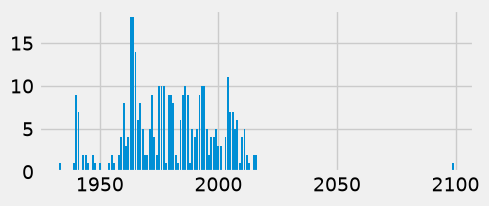

In [53]:
counts = get_sorted_counts(years, sort='year')
x, y = np.array(counts).transpose()
plt.bar(x, y)
plt.show()

Il grafico appare "spostato" verso sinistra, a causa della presenza di una barra in prossimità dell'anno 2100. Potrebbe essere un supereroe effettivamente nato nel futuro, oppure si potrebbe trattare di un dato errato. Si tratta di una situazione più comune di quanto non si possa pensare: queste misurazioni affette da rumore prendono il nome di _dati fuori scala_ o _outlier_. Per ora limitiamoci a vedere quale sia questo valore. Possiamo farlo usando una list comprehension appena più complicata di quella vista poco fa:

In [54]:
[year for year in years if year > 2020]

[2099]

In soldoni, la presenza dell'anno 2099 causa lo spostamento del grafico. Potremmo eliminare il record corrispondente dal nostro dataset, ma così facendo perderemmo i valori per gli altri campi che non è detto siano anch'essi degli outlier. Un modo molto più pratico di procedere è quello di visualizzare il grafico restringendo le ascisse all'intervallo temporale che va dal 1950 al 2015: ciò viene fatto invocando la funzione `plt.xlim` e passandole una coppia con gli estremi di questo intervallo. Già che ci siamo, possiamo anche impostare l'ampiezza dell'asse delle ordinate in modo che ci sia un po' di spazio sopra la barra che corrisponde alla frequenza massima:

In [55]:
tuple([42])

(42,)

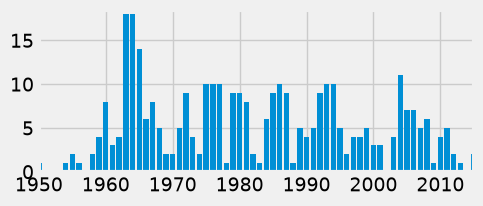

In [57]:
plt.bar(x, y)
plt.xlim((1950, 2015))
plt.ylim((0, 18.5))
plt.show()

<div class="alert alert-info">
    In teoria, una volta ottenuta la lista <code>counts</code>, è possibile generare il grafico (ridimensionamento dei suoi assi a parte) usando l'istruzione più compatta <code>plt.bar(counts[1:]).T)</code> in cui
    <ul>
    <li>l'invocazione del metodo <code>transpose</code> è sostituita dall'utilizzo della proprietà <code>T</code>: si tratta essenzialmente della stessa cosa, ma permette di essere più succinti;</li>
    <li>invece di assegnare a due variabili 'x' e 'y' le liste di ascisse e ordinate, si usa l'operatore <code>*</code> per effettuare un'altra forma di unpacking delle liste in modo che i due elementi della lista restituita da <code>T</code> vengano rispettivamente usati come primo e secondo argomento di <code>np.bar</code>.</li>
    </ul>
    Va in ogni caso sottolineato che il minor numero di linee si paga con del codice più complesso e quindi meno facile da leggere e da correggere in caso di errore, quindi almeno fino a quando non si è abbastanza confidenti nel linguaggio è meglio non ricorrere a soluzioni troppo complicate.
</div>